# Model and drivers

Status update for the consultation, 6 Nov 2026. This notebook reads the saved results from the analysis folders, so it runs in seconds and does not refit anything.

Four questions:
1. How many features should the model use?
2. How well does it predict?
3. What drives the prediction?
4. Where does PCA fit now?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
root = Path('../..')
xai = root / '02_xgboost_xai'
pca = root / '01_pca_diagnostic'

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. How many features?

The old 44 came from the PCA recipe (top 10 components, top 5 loadings each), not from a performance check. We replaced it with a sweep. For each k, we rank the survey variables inside every training fold, keep the top k, and score on the held-out fold. Folds are grouped by household.

In [3]:
sweep = pd.read_csv(xai / 'sweep_cv_summary.csv')
sweep[['k', 'n_dummies', 'auc_mean', 'auc_sd', 'pr_mean']].round(4)

,k,n_dummies,auc_mean,auc_sd,pr_mean
0,5,60.0,0.6804,0.0033,0.4796
1,8,93.2,0.6858,0.0022,0.4864
2,10,120.4,0.6887,0.0034,0.4916
3,15,179.4,0.6942,0.0016,0.5008
4,20,237.4,0.6971,0.0020,0.5035
5,25,293.8,0.6993,0.0014,0.5067
6,30,321.6,0.7011,0.0017,0.5098
7,40,384.6,0.7036,0.0015,0.5122
8,50,436.8,0.7044,0.0019,0.5130
9,60,502.2,0.7062,0.0020,0.5145


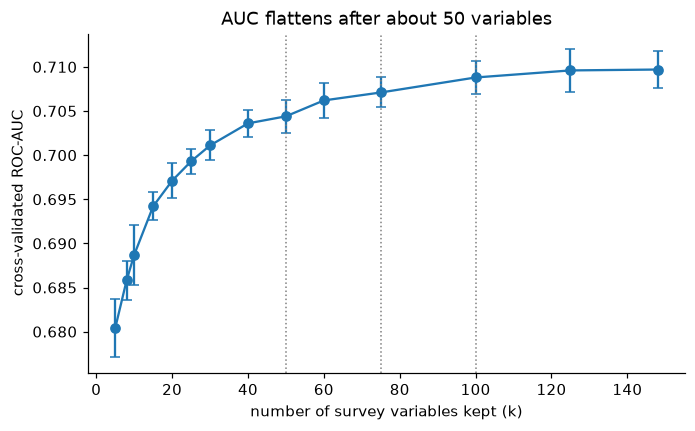

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(sweep.k, sweep.auc_mean, yerr=sweep.auc_sd, marker='o', capsize=3, color='tab:blue')
for k in (50, 75, 100):
    ax.axvline(k, color='grey', ls=':', lw=1)
ax.set_xlabel('number of survey variables kept (k)')
ax.set_ylabel('cross-validated ROC-AUC')
ax.set_title('AUC flattens after about 50 variables')
plt.show()

The curve is flat past 50. Going from 75 variables to all 148 adds about 0.003 AUC.

The strict one-standard-error rule picks k = 100. We use **k = 75** because it is on the flat part and its selected set is the most stable across folds (see below). This is our judgement call and we want the adviser's view on it.

In [5]:
stab = pd.read_csv(xai / 'sweep_stability_by_k.csv')
stab[stab.k.isin([25, 50, 75, 100])][['k', 'mean_pairwise_jaccard']]

,k,mean_pairwise_jaccard
5,25,0.861
8,50,0.803
10,75,0.909
11,100,0.868


## 2. How well does it predict?

The test set is held out by household. Everything is weighted with the survey weight.

In [6]:
m = pd.read_csv(xai / 'primary_model_metrics.csv').round(3)
m

,roc_auc_weighted,pr_auc_weighted,roc_auc_unweighted
0,0.711,0.516,0.716


ROC-AUC is the chance that a randomly chosen illiterate person gets a higher risk score than a randomly chosen literate person. 0.5 is a coin flip. At 0.71 the model ranks people moderately well. It is not sharp enough to screen individuals, so we frame it as an area-level tool.

Earlier checks, all on the 45-feature model, did not change this:

In [7]:
sc = pd.read_csv(xai / 'leakage_audit_scenarios.csv')
sc['scenario'] = sc.scenario.str.replace(' (primary)', '', regex=False)
sc.round(4)

,scenario,n_features,roc_auc_weighted,pr_auc_weighted,roc_auc_unweighted
0,"S0 Phase 1B list (all-rows selection), grouped...",43,0.7005,0.5155,0.7068
1,S1 train-only selection,44,0.6996,0.5160,0.7083
2,"S2 train-only, READ_IND_F3 excluded",44,0.7010,0.5042,0.7074
3,S3 S2 plus TVOC* excluded,44,0.7004,0.5038,0.7067
4,S2b S2 plus AGE forced (ALE model),45,0.7019,0.5051,0.7082
5,S4 top-75 original variables,551,0.7110,0.5160,0.7162


- Choosing features on all rows instead of training rows only made no difference (first two rows).
- We dropped `READ_IND_F3` because it restates the outcome (93.9% of people coded 2 are illiterate). Dropping it cost no ROC-AUC.
- The last row is the current 75-variable model.

## 3. What drives the prediction?

SHAP measures how much each variable moves a person's predicted risk. We add up the dummies of each original variable, and treat the digital-skill items as one block.

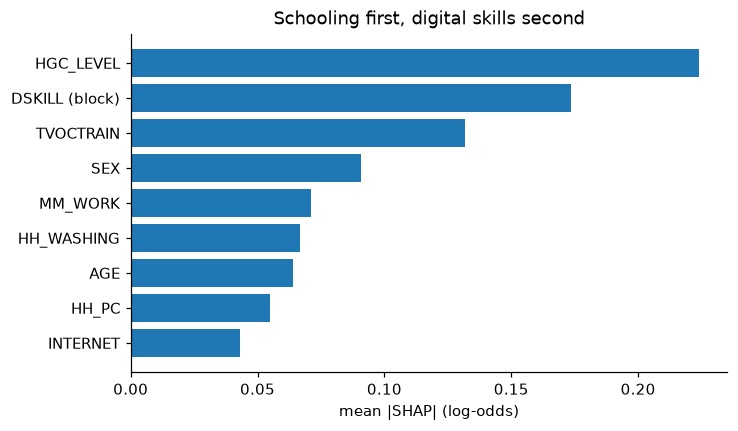

In [8]:
g = pd.read_csv(xai / 'shap_grouped_importance_audited.csv')
g = g[~g.Group.str.startswith('DSKILL_')]
g = g.sort_values('Mean_abs_SHAP').tail(9)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(g.Group, g.Mean_abs_SHAP, color='tab:blue')
ax.set_xlabel('mean |SHAP| (log-odds)')
ax.set_title('Schooling first, digital skills second')
plt.show()

Schooling (`HGC_LEVEL`) is first and the digital-skill block is second. An older export had digital skills first. That came from the pre-audit pipeline and should not be quoted.

SHAP gives size. For direction we use ALE, which compares each answer against the baseline level. An odds ratio below 1 means lower odds of illiteracy.

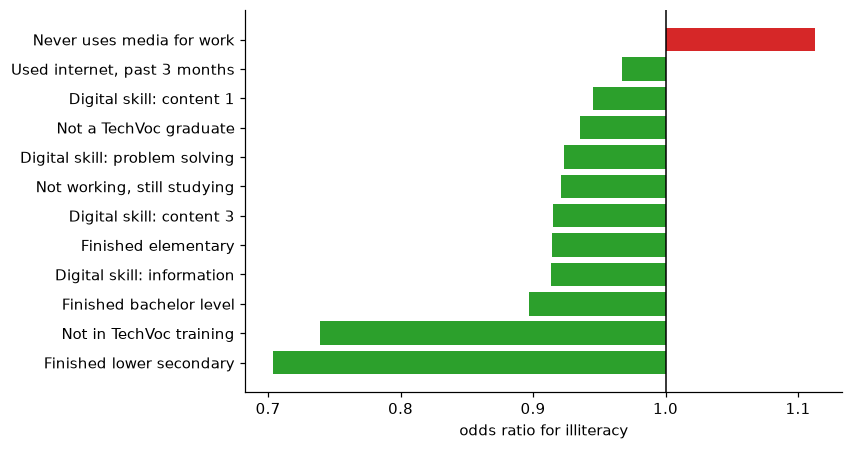

In [9]:
ale = pd.read_csv(xai / 'ale_effect_summary.csv')
ale = ale[ale.Type == 'binary'].copy()
short = {
    'TVOCTRAIN_5': 'Not in TechVoc training',
    'HGC_LEVEL_2': 'Finished lower secondary',
    'HGC_LEVEL_6': 'Finished bachelor level',
    'HGC_LEVEL_1': 'Finished elementary',
    'DSKILL_INFO2_1': 'Digital skill: information',
    'DSKILL_CONT3_1': 'Digital skill: content 3',
    'DSKILL_PROB6_1': 'Digital skill: problem solving',
    'NOWORK_REASON_ 1': 'Not working, still studying',
    'TVOCGRAD_5': 'Not a TechVoc graduate',
    'DSKILL_CONT1_1': 'Digital skill: content 1',
    'INTERNET_1': 'Used internet, past 3 months',
    'MM_WORK_1': 'Never uses media for work',
}
ale['label'] = ale.Feature.map(short)
ale = ale.sort_values('Odds_ratio_0_to_1')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(ale.label, ale.Odds_ratio_0_to_1 - 1, left=1,
        color=np.where(ale.Odds_ratio_0_to_1 < 1, 'tab:green', 'tab:red'))
ax.axvline(1, color='black', lw=1)
ax.set_xlabel('odds ratio for illiteracy')
plt.show()

Caution: per-dummy schooling effects are smaller than in the 45-feature run (elementary 0.91 now, 0.52 before). Schooling is now spread over several dummies, so we quote the grouped SHAP for its size and not these single odds ratios.

Do the drivers interact? Friedman's H² says how much of the model is more than the sum of its parts. We keep only pairs where the data contain every combination.

In [10]:
h = pd.read_csv(xai / 'friedman_h_pairs.csv')
h = h[h.Supported][['Feature_A', 'Feature_B', 'H2']].round(3)
h

,Feature_A,Feature_B,H2
0,HGC_LEVEL_1,INTERNET_1,0.054
3,AGE,HGC_LEVEL_1,0.029
4,DSKILL_PROB6_1,TVOCTRAIN_5,0.015
5,DSKILL_CONT1_1,TVOCTRAIN_5,0.014


All supported pairs are small (H² at most 0.054). The model is close to additive, which is why adding the digital-skill and internet effects in the simulation is reasonable.

## 4. Where does PCA fit?

PCA is now a diagnostic, not a selector. An earlier benchmark compared a model on PCA components with a model on 44 selected features (older split):

In [11]:
cmp = pd.read_csv(pca / 'pca_component_xgboost_comparison.csv')
cmp[['Model', 'Input_Features', 'ROC_AUC', 'PR_AUC']].round(3)

,Model,Input_Features,ROC_AUC,PR_AUC
0,PCA components (95% variance),533,0.713,0.530
1,Supervised original features,44,0.702,0.519


PCA keeps the predictive signal (it is even 0.011 higher), but it needs 533 components, one-hot encoding spreads variance thinly (504 components for 95%), and components cannot be read as survey questions. The case for supervised selection is a small, readable feature list, not accuracy.

What PCA does tell us: the variance in the survey sits mostly in digital, media and routing items (many "Not Applicable" levels), while schooling, the strongest predictor, is a smaller source of variance. Variance order and relevance to the target have a rank correlation of only 0.65, and the best single component reaches AUC 0.61.